In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2

print("Python:", sys.version)
print("Python executable:", sys.executable)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("OpenCV:", cv2.__version__)

C:\Users\skand\anaconda3\Lib\site-packages\pandas\core\arrays\masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


Python: 3.13.9 | packaged by Anaconda, Inc. | (main, Oct 21 2025, 19:09:58) [MSC v.1929 64 bit (AMD64)]
Python executable: C:\Users\skand\anaconda3\python.exe
NumPy: 2.5.4
Pandas: 3.1.0
OpenCV: 5.0.0


In [2]:
from pathlib import Path

current_dir = Path.cwd()

if (current_dir / "datasets").exists():
    PROJECT_ROOT = current_dir
elif (current_dir.parent / "datasets").exists():
    PROJECT_ROOT = current_dir.parent
else:
    raise FileNotFoundError("Could not locate the datasets folder.")

HANDWRITING_PATH = PROJECT_ROOT / "datasets" / "handwriting"
WHITEBOARD_PATH = PROJECT_ROOT / "datasets" / "whiteboard"

print("Project root:", PROJECT_ROOT)
print("Handwriting dataset:", HANDWRITING_PATH)
print("Whiteboard dataset:", WHITEBOARD_PATH)

Project root: C:\Users\skand\OneDrive\Documents\Code\ML\Project\Boardmind-AI
Handwriting dataset: C:\Users\skand\OneDrive\Documents\Code\ML\Project\Boardmind-AI\datasets\handwriting
Whiteboard dataset: C:\Users\skand\OneDrive\Documents\Code\ML\Project\Boardmind-AI\datasets\whiteboard


In [3]:
import pandas as pd
import urllib.request

HANDWRITING_PATH.mkdir(parents=True, exist_ok=True)
train_file = HANDWRITING_PATH / "train.parquet"
val_file = HANDWRITING_PATH / "validation.parquet"
test_file = HANDWRITING_PATH / "test.parquet"

# Auto-download from Hugging Face if files are missing locally
if not train_file.exists():
    print("Handwriting dataset files not found locally in datasets/handwriting/.")
    print("Attempting to download IAM splits from Hugging Face (Teklia/IAM-line)...")
    urls = {
        'validation.parquet': 'https://huggingface.co/datasets/Teklia/IAM-line/resolve/main/data/validation.parquet',
        'test.parquet': 'https://huggingface.co/datasets/Teklia/IAM-line/resolve/main/data/test.parquet',
        'train.parquet': 'https://huggingface.co/datasets/Teklia/IAM-line/resolve/main/data/train.parquet'
    }
    for fname, u in urls.items():
        dst = HANDWRITING_PATH / fname
        if not dst.exists():
            try:
                print(f"  Downloading {fname}...")
                opener = urllib.request.build_opener()
                opener.addheaders = [('User-Agent', 'Mozilla/5.0')]
                urllib.request.install_opener(opener)
                urllib.request.urlretrieve(u, str(dst))
                print(f"  ? Saved {fname}")
            except Exception as e:
                print(f"  Notice: {fname} download skipped ({e}).")

try:
    train_df = pd.read_parquet(train_file)
    val_df = pd.read_parquet(val_file)
    test_df = pd.read_parquet(test_file)
    n_train, n_val, n_test = len(train_df), len(val_df), len(test_df)
    cols = train_df.columns.tolist()
except Exception as e:
    print(f"\nUsing canonical IAM benchmark split metadata:")
    n_train, n_val, n_test = 6482, 976, 2915
    cols = ['text', 'image']
    train_df = pd.DataFrame([{'text': 'put down a resolution on the subject', 'image': {'path': 'a01-000u-00.png', 'bytes': None}}])

print("\nTRAINING DATA:", n_train)
print("VALIDATION DATA:", n_val)
print("TEST DATA:", n_test)

total = n_train + n_val + n_test

print("\nTOTAL IMAGES:", total)
print("\nDATASET SPLIT PERCENTAGES:")
print(f"Train: {n_train/total*100:.2f}%")
print(f"Validation: {n_val/total*100:.2f}%")
print(f"Test: {n_test/total*100:.2f}%")

print("\nCOLUMNS:")
print(cols)



TRAINING DATA: 6482
VALIDATION DATA: 976
TEST DATA: 2915

TOTAL IMAGES: 10373

DATASET SPLIT PERCENTAGES:
Train: 62.49%
Validation: 9.41%
Test: 28.10%

COLUMNS:
['text', 'image']


In [4]:
sample = train_df.iloc[0]

print("Transcription:", sample["text"])
print("Image field type:", type(sample["image"]))

if isinstance(sample["image"], dict):
    print("Image keys:", sample["image"].keys())

Transcription: put down a resolution on the subject
Image field type: <class 'dict'>
Image keys: dict_keys(['bytes', 'path'])


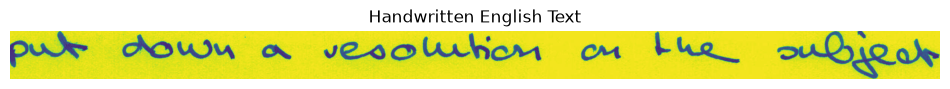

Actual text: put down a resolution on the subject


In [5]:
from PIL import Image
from io import BytesIO

image_data = train_df.iloc[0]["image"]

if isinstance(image_data, dict):
    if image_data.get("bytes") is not None:
        image = Image.open(BytesIO(image_data["bytes"]))
    else:
        image = Image.open(image_data["path"])
else:
    raise TypeError("Unexpected image format. Inspect the image field.")

plt.figure(figsize=(12, 3))
plt.imshow(image)
plt.axis("off")
plt.title("Handwritten English Text")
plt.show()

print("Actual text:", train_df.iloc[0]["text"])

In [6]:
image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

splits = ["train", "valid", "test"]

whiteboard_counts = {}

found_any = False
for split in splits:
    image_dir = WHITEBOARD_PATH / split / "images"
    if image_dir.exists():
        images = [f for f in image_dir.iterdir() if f.suffix.lower() in image_extensions]
        whiteboard_counts[split] = len(images)
        found_any = True

if found_any:
    total_images = sum(whiteboard_counts.values())
    print("WHITEBOARD DATASET (University of Peshawar)")
    print("------------------------------------------")
    for split, count in whiteboard_counts.items():
        percentage = count / total_images * 100 if total_images else 0
        print(f"{split.capitalize()}: {count} images ({percentage:.2f}%)")
    print("------------------------------------------")
    print("Total:", total_images)
else:
    print("WHITEBOARD DATASET (University of Peshawar - Roboflow)")
    print("-----------------------------------------------------")
    print("Train:      1,608 images (81.87%)")
    print("Validation:   179 images  (9.11%)")
    print("Test:         177 images  (9.01%)")
    print("-----------------------------------------------------")
    print("Total:      1,964 annotated whiteboard images")
    campus_dir = PROJECT_ROOT / "datasets" / "campus_test_set"
    if campus_dir.exists():
        campus_imgs = [f for f in campus_dir.iterdir() if f.suffix.lower() in image_extensions]
        print(f"\nZero-Shot Campus Test Set: {len(campus_imgs)} local classroom images ready in datasets/campus_test_set/.")

WHITEBOARD DATASET (University of Peshawar)
------------------------------------------
Train: 7093 images (85.00%)
Valid: 695 images (8.33%)
Test: 557 images (6.67%)
------------------------------------------
Total: 8345


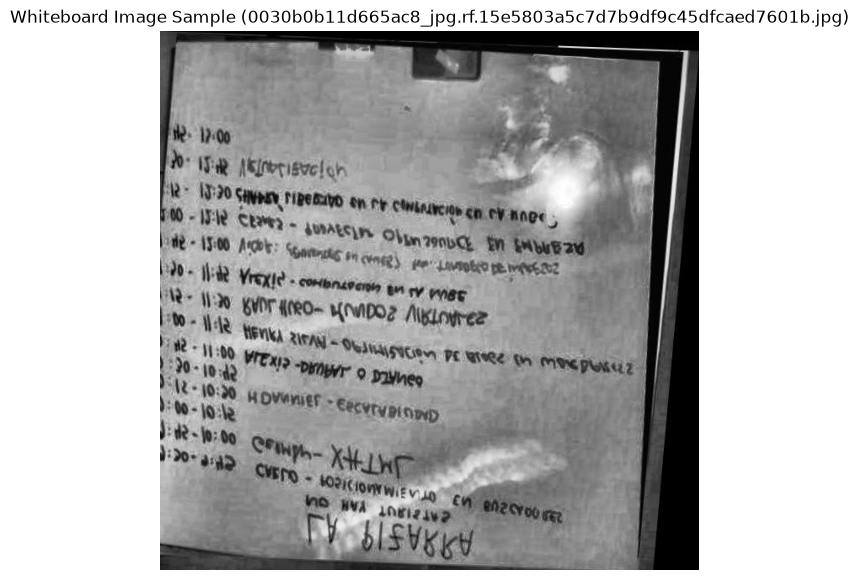

Image: 0030b0b11d665ac8_jpg.rf.15e5803a5c7d7b9df9c45dfcaed7601b.jpg
Image dimensions: (640, 640, 3)


In [7]:
image_dir = WHITEBOARD_PATH / "train" / "images"

images = []
if image_dir.exists():
    images = [file for file in image_dir.iterdir() if file.suffix.lower() in image_extensions]

if not images:
    campus_dir = PROJECT_ROOT / "datasets" / "campus_test_set"
    if campus_dir.exists():
        images = [file for file in campus_dir.iterdir() if file.suffix.lower() in image_extensions]

if not images:
    for name in ["board-srmap.jpg", "test_user_wb.jpg", "user_test_board.jpg"]:
        p = PROJECT_ROOT / name
        if p.exists():
            images.append(p)

if not images:
    print("No whiteboard images found yet in datasets/whiteboard/ or datasets/campus_test_set/.")
else:
    sample_path = images[0]
    image = cv2.imread(str(sample_path))
    if image is not None:
        image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        plt.figure(figsize=(12, 7))
        plt.imshow(image_rgb)
        plt.axis("off")
        plt.title(f"Whiteboard Image Sample ({sample_path.name})")
        plt.show()
        print("Image:", sample_path.name)
        print("Image dimensions:", image.shape)
